In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
# Replace these names only if your uploaded filenames are different
purchase_df = pd.read_csv("car_purchase_classification_200.csv")
condition_df = pd.read_csv("used_car_condition_classification_200.csv")

print("Car Purchase Dataset Shape:", purchase_df.shape)
print("Used Car Condition Dataset Shape:", condition_df.shape)

Car Purchase Dataset Shape: (200, 12)
Used Car Condition Dataset Shape: (200, 12)


In [3]:
print("=== Car Purchase Dataset ===")
display(purchase_df.head())
print(purchase_df.info())
print("\nMissing values:\n", purchase_df.isnull().sum())
print("\nTarget distribution:\n", purchase_df["buy_car"].value_counts())

print("\n\n=== Used Car Condition Dataset ===")
display(condition_df.head())
print(condition_df.info())
print("\nMissing values:\n", condition_df.isnull().sum())
print("\nTarget distribution:\n", condition_df["condition_class"].value_counts())

=== Car Purchase Dataset ===


,age,annual_income,family_size,daily_commute_km,credit_score,currently_owns_car,ev_interest_score,preferred_brand,preferred_fuel,transmission_preference,body_type,buy_car
0,56,33795,5,16,556,1,5,Honda,Gasoline,Automatic,Hatchback,0
1,41,59090,6,54,707,1,6,BMW,Gasoline,Automatic,SUV,1
2,38,101104,4,59,471,0,9,Honda,Gasoline,Automatic,Pickup,1
3,45,20747,6,63,624,1,7,Toyota,Electric,Automatic,Sedan,0
4,20,87092,3,8,470,1,2,BMW,Electric,Automatic,Sedan,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   age                      200 non-null    int64 
 1   annual_income            200 non-null    int64 
 2   family_size              200 non-null    int64 
 3   daily_commute_km         200 non-null    int64 
 4   credit_score             200 non-null    int64 
 5   currently_owns_car       200 non-null    int64 
 6   ev_interest_score        200 non-null    int64 
 7   preferred_brand          200 non-null    object
 8   preferred_fuel           200 non-null    object
 9   transmission_preference  200 non-null    object
 10  body_type                200 non-null    object
 11  buy_car                  200 non-null    int64 
dtypes: int64(8), object(4)
memory usage: 18.9+ KB
None

Missing values:
 age                        0
annual_income              0
family_size          

,car_age_years,mileage_km,number_of_owners,engine_size_l,service_history,accident_history,fuel_type,brand,transmission,tire_wear_percent,battery_health_percent,condition_class
0,9,37779,1,2.0,Occasional,NaN,Petrol,Hyundai,Automatic,19,82,Good
1,2,163059,3,2.3,Occasional,NaN,Diesel,BMW,Manual,84,86,Average
2,5,92163,3,1.6,Poor,NaN,Hybrid,Suzuki,Manual,25,52,Poor
3,13,186187,4,2.3,Occasional,Major,Hybrid,Suzuki,Manual,32,74,Poor
4,8,126999,2,2.5,Occasional,NaN,Hybrid,Suzuki,Manual,8,65,Average


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   car_age_years           200 non-null    int64  
 1   mileage_km              200 non-null    int64  
 2   number_of_owners        200 non-null    int64  
 3   engine_size_l           200 non-null    float64
 4   service_history         200 non-null    object 
 5   accident_history        72 non-null     object 
 6   fuel_type               200 non-null    object 
 7   brand                   200 non-null    object 
 8   transmission            200 non-null    object 
 9   tire_wear_percent       200 non-null    int64  
 10  battery_health_percent  200 non-null    int64  
 11  condition_class         200 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 18.9+ KB
None

Missing values:
 car_age_years               0
mileage_km                  0
number_

In [12]:
def run_classification_analysis(df, target_col, dataset_name):
    print(f"\n{'='*70}")
    print(f"DATASET: {dataset_name}")
    print(f"{'='*70}")

    # Separate features and target
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Identify column types
    numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
    categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

    print("\nNumeric Features:", numeric_features)
    print("Categorical Features:", categorical_features)

    # Preprocessing for numeric data
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Preprocessing for categorical data
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine preprocessing
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Define models
    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
        "SVM": SVC(kernel="rbf", probability=True, random_state=42),
        "KNN": KNeighborsClassifier(n_neighbors=5)
    }

    results = []

    for model_name, model in models.items():
        print(f"\n{'-'*60}")
        print(f"Training: {model_name}")
        print(f"{'-'*60}")

        # Build pipeline
        clf = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ])

        # Train
        clf.fit(X_train, y_train)

        # Predict
        y_pred = clf.predict(X_test)

        # Metrics
        accuracy = accuracy_score(y_test, y_pred)

        # Binary or multiclass metric setting
        avg_type = "binary" if y.nunique() == 2 else "weighted"

        precision = precision_score(y_test, y_pred, average=avg_type, zero_division=0)
        recall = recall_score(y_test, y_pred, average=avg_type, zero_division=0)
        f1 = f1_score(y_test, y_pred, average=avg_type, zero_division=0)

        results.append({
            "Dataset": dataset_name,
            "Algorithm": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        })

        print(f"Accuracy : {accuracy:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall   : {recall:.4f}")
        print(f"F1-Score : {f1:.4f}")

        print("\nClassification Report:")
        print(classification_report(y_test, y_pred, zero_division=0))

        # Confusion matrix
        plt.figure(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
        plt.title(f"{dataset_name} - {model_name}")
        plt.show()

    results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)

    print(f"\nSummary of Results for {dataset_name}:")
    display(results_df)

    return results_df


DATASET: Car Purchase Classification

Numeric Features: ['age', 'annual_income', 'family_size', 'daily_commute_km', 'credit_score', 'currently_owns_car', 'ev_interest_score']
Categorical Features: ['preferred_brand', 'preferred_fuel', 'transmission_preference', 'body_type']

------------------------------------------------------------
Training: Logistic Regression
------------------------------------------------------------
Accuracy : 0.7000
Precision: 0.6667
Recall   : 0.9091
F1-Score : 0.7692

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.44      0.57        18
           1       0.67      0.91      0.77        22

    accuracy                           0.70        40
   macro avg       0.73      0.68      0.67        40
weighted avg       0.73      0.70      0.68        40



<Figure size 500x400 with 0 Axes>

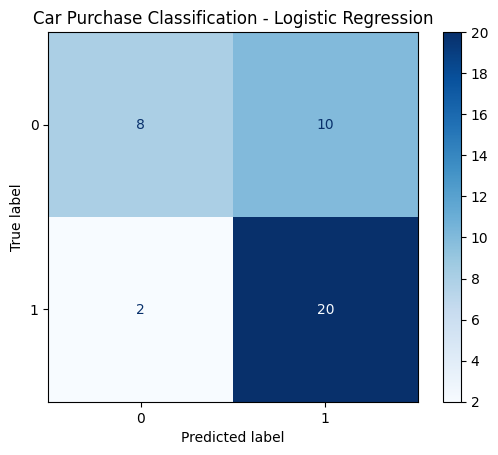


------------------------------------------------------------
Training: Random Forest
------------------------------------------------------------
Accuracy : 0.6250
Precision: 0.6296
Recall   : 0.7727
F1-Score : 0.6939

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.44      0.52        18
           1       0.63      0.77      0.69        22

    accuracy                           0.62        40
   macro avg       0.62      0.61      0.61        40
weighted avg       0.62      0.62      0.61        40



<Figure size 500x400 with 0 Axes>

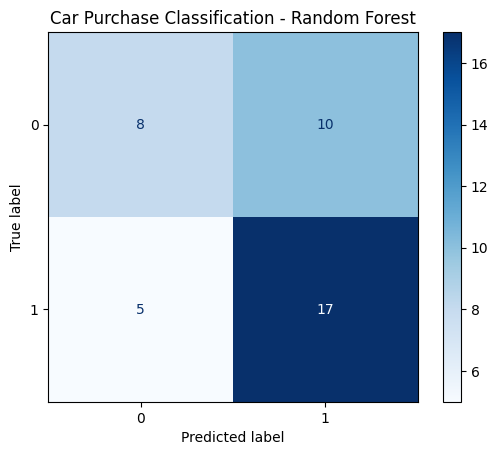


------------------------------------------------------------
Training: SVM
------------------------------------------------------------
Accuracy : 0.6750
Precision: 0.6552
Recall   : 0.8636
F1-Score : 0.7451

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.44      0.55        18
           1       0.66      0.86      0.75        22

    accuracy                           0.68        40
   macro avg       0.69      0.65      0.65        40
weighted avg       0.69      0.68      0.66        40



<Figure size 500x400 with 0 Axes>

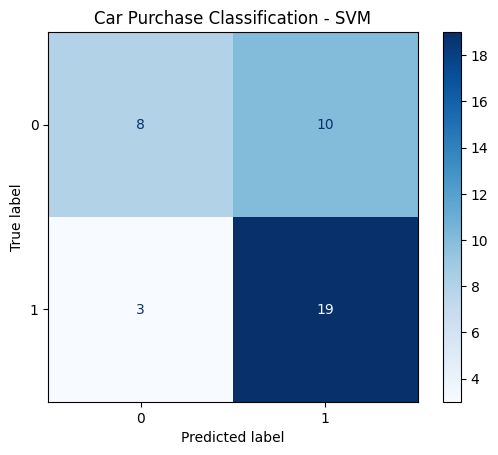


------------------------------------------------------------
Training: KNN
------------------------------------------------------------
Accuracy : 0.6250
Precision: 0.6400
Recall   : 0.7273
F1-Score : 0.6809

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.50      0.55        18
           1       0.64      0.73      0.68        22

    accuracy                           0.62        40
   macro avg       0.62      0.61      0.61        40
weighted avg       0.62      0.62      0.62        40



<Figure size 500x400 with 0 Axes>

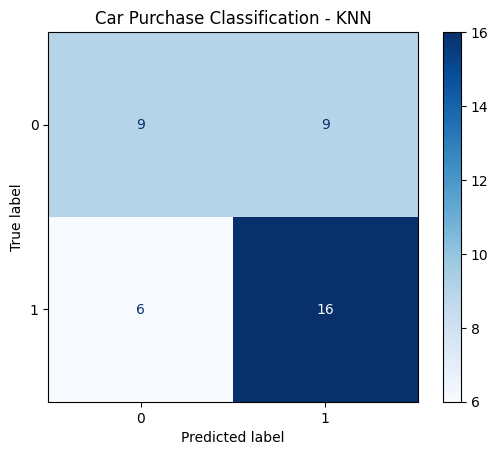


Summary of Results for Car Purchase Classification:


,Dataset,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Car Purchase Classification,Logistic Regression,0.700,0.666667,0.909091,0.769231
2,Car Purchase Classification,SVM,0.675,0.655172,0.863636,0.745098
1,Car Purchase Classification,Random Forest,0.625,0.629630,0.772727,0.693878
3,Car Purchase Classification,KNN,0.625,0.640000,0.727273,0.680851


In [7]:
purchase_results = run_classification_analysis(
    df=purchase_df,
    target_col="buy_car",
    dataset_name="Car Purchase Classification"
)


DATASET: Used Car Condition Classification

Numeric Features: ['car_age_years', 'mileage_km', 'number_of_owners', 'engine_size_l', 'tire_wear_percent', 'battery_health_percent']
Categorical Features: ['service_history', 'accident_history', 'fuel_type', 'brand', 'transmission']

------------------------------------------------------------
Training: Logistic Regression
------------------------------------------------------------
Accuracy : 0.5250
Precision: 0.5457
Recall   : 0.5250
F1-Score : 0.5294

Classification Report:
              precision    recall  f1-score   support

     Average       0.47      0.56      0.51        16
        Good       0.75      0.55      0.63        11
        Poor       0.46      0.46      0.46        13

    accuracy                           0.53        40
   macro avg       0.56      0.52      0.54        40
weighted avg       0.55      0.53      0.53        40



<Figure size 500x400 with 0 Axes>

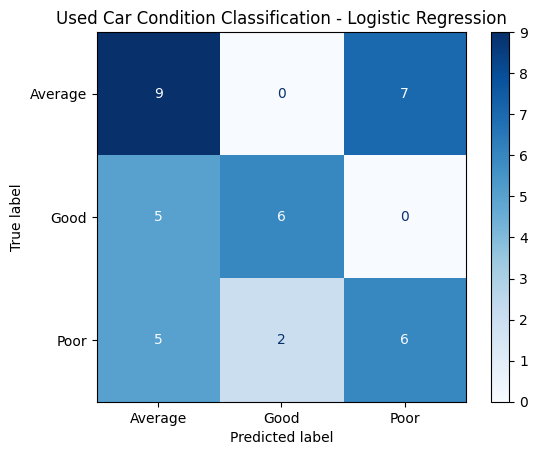


------------------------------------------------------------
Training: Random Forest
------------------------------------------------------------
Accuracy : 0.6500
Precision: 0.7341
Recall   : 0.6500
F1-Score : 0.6465

Classification Report:
              precision    recall  f1-score   support

     Average       0.54      0.88      0.67        16
        Good       1.00      0.55      0.71        11
        Poor       0.75      0.46      0.57        13

    accuracy                           0.65        40
   macro avg       0.76      0.63      0.65        40
weighted avg       0.73      0.65      0.65        40



<Figure size 500x400 with 0 Axes>

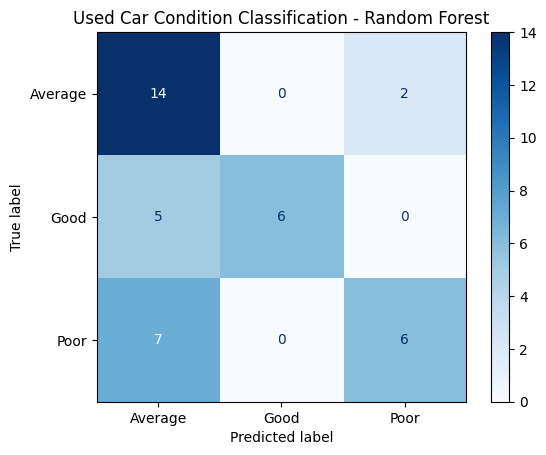


------------------------------------------------------------
Training: SVM
------------------------------------------------------------
Accuracy : 0.5250
Precision: 0.5596
Recall   : 0.5250
F1-Score : 0.5094

Classification Report:
              precision    recall  f1-score   support

     Average       0.46      0.75      0.57        16
        Good       0.86      0.55      0.67        11
        Poor       0.43      0.23      0.30        13

    accuracy                           0.53        40
   macro avg       0.58      0.51      0.51        40
weighted avg       0.56      0.53      0.51        40



<Figure size 500x400 with 0 Axes>

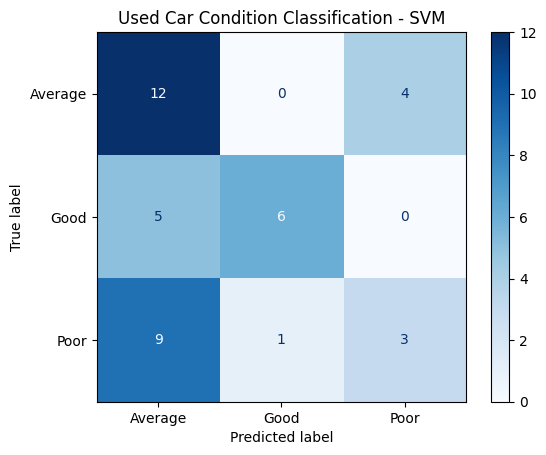


------------------------------------------------------------
Training: KNN
------------------------------------------------------------
Accuracy : 0.4250
Precision: 0.4702
Recall   : 0.4250
F1-Score : 0.4128

Classification Report:
              precision    recall  f1-score   support

     Average       0.37      0.62      0.47        16
        Good       0.83      0.45      0.59        11
        Poor       0.29      0.15      0.20        13

    accuracy                           0.42        40
   macro avg       0.50      0.41      0.42        40
weighted avg       0.47      0.42      0.41        40



<Figure size 500x400 with 0 Axes>

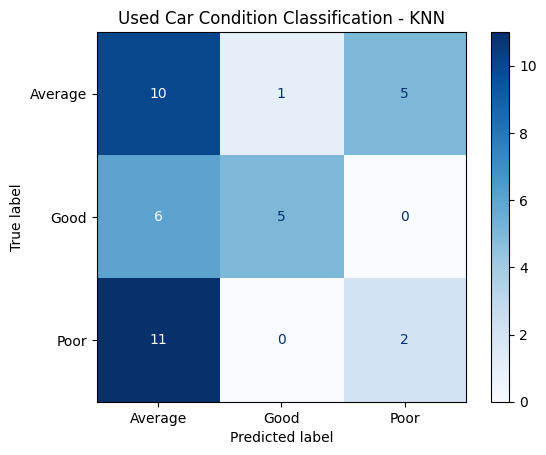


Summary of Results for Used Car Condition Classification:


,Dataset,Algorithm,Accuracy,Precision,Recall,F1-Score
1,Used Car Condition Classification,Random Forest,0.650,0.734135,0.650,0.646499
0,Used Car Condition Classification,Logistic Regression,0.525,0.545724,0.525,0.529398
2,Used Car Condition Classification,SVM,0.525,0.559615,0.525,0.509405
3,Used Car Condition Classification,KNN,0.425,0.470172,0.425,0.412811


In [8]:
condition_results = run_classification_analysis(
    df=condition_df,
    target_col="condition_class",
    dataset_name="Used Car Condition Classification"
)

In [13]:
all_results = pd.concat([purchase_results, condition_results], ignore_index=True)

print("=== Overall Model Performance Comparison ===")
display(all_results.sort_values(by=["Dataset", "Accuracy"], ascending=[True, False]))

=== Overall Model Performance Comparison ===


,Dataset,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Car Purchase Classification,Logistic Regression,0.700,0.666667,0.909091,0.769231
1,Car Purchase Classification,SVM,0.675,0.655172,0.863636,0.745098
2,Car Purchase Classification,Random Forest,0.625,0.629630,0.772727,0.693878
3,Car Purchase Classification,KNN,0.625,0.640000,0.727273,0.680851
4,Used Car Condition Classification,Random Forest,0.650,0.734135,0.650000,0.646499
5,Used Car Condition Classification,Logistic Regression,0.525,0.545724,0.525000,0.529398
6,Used Car Condition Classification,SVM,0.525,0.559615,0.525000,0.509405
7,Used Car Condition Classification,KNN,0.425,0.470172,0.425000,0.412811


In [14]:
best_models = all_results.loc[all_results.groupby("Dataset")["Accuracy"].idxmax()].reset_index(drop=True)

print("=== Best Model for Each Dataset ===")
display(best_models)

=== Best Model for Each Dataset ===


,Dataset,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Car Purchase Classification,Logistic Regression,0.70,0.666667,0.909091,0.769231
1,Used Car Condition Classification,Random Forest,0.65,0.734135,0.650000,0.646499
